# Proyek Analisis Data: [Input Nama Dataset]
- **Nama:** Nita Rahmawati
- **Email:** nitarahmawatira@gmail.com
- **ID Dicoding:** DS009B6X1383

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa yang memiliki pertumbuhan pendapatan (dalam Real Brasil) tertinggi dari pesanan berstatus delivered pada periode Januari-Agustus 2018 dibandingkan Januari-Agustus 2017, dan berapa persen kontribusi masing-masing kategori terhadap total pendapatan 2018?
- **Pertanyaan 2:** Berapa selisih rata-rata review score antara pesanan yang tiba tepat waktu dan yang terlambat dari estimasi pada pesanan delivered selama Januari 2017 sampai Agustus 2018?

**Catatan:** Seluruh nilai uang dalam dataset ini menggunakan Real Brasil (R$) sesuai dokumentasi dataset Olist di Kaggle. Kolom data itu sendiri tidak mencantumkan mata uang.

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print(pd.__version__)

3.0.6


## Data Wrangling

### Gathering Data

#### Load Data

In [2]:
customers_df = pd.read_csv("data/customers_dataset.csv")
geolocation_df = pd.read_csv("data/geolocation_dataset.csv")
order_items_df = pd.read_csv("data/order_items_dataset.csv")
order_payments_df = pd.read_csv("data/order_payments_dataset.csv")
order_reviews_df = pd.read_csv("data/order_reviews_dataset.csv")
orders_df = pd.read_csv("data/orders_dataset.csv")
category_df = pd.read_csv("data/product_category_name_translation.csv")
products_df = pd.read_csv("data/products_dataset.csv")
sellers_df = pd.read_csv("data/sellers_dataset.csv")

In [3]:
tabel = {
    "customers": customers_df, "geolocation": geolocation_df,
    "order_items": order_items_df, "order_payments": order_payments_df,
    "order_reviews": order_reviews_df, "orders": orders_df,
    "category": category_df, "products": products_df, "sellers": sellers_df,
}
for nama, df in tabel.items():
    print(f"{nama:15} {df.shape}")

customers       (99441, 5)
geolocation     (1000163, 5)
order_items     (112650, 7)
order_payments  (103886, 5)
order_reviews   (99224, 7)
orders          (99441, 8)
category        (71, 2)
products        (32951, 9)
sellers         (3095, 4)


**Insight:** (Opsional)
- Dataset terdiri dari 9 tabel yang saling terhubung lewat kunci seperti order_id, customer_id, product_id, dan seller_id.
- Tabel geolocation paling besar (1.000.163 baris), sedangkan tabel inti transaksi yaitu orders berisi 99.441 baris dan order_items 112.650 baris.
- Tabel category (71 baris) berfungsi sebagai kamus terjemahan nama kategori produk dari bahasa Portugis ke Inggris.

### Assessing Data

#### Mengecek struktur dan tipe data

In [4]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
orders_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


In [6]:
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [7]:
order_items_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB


In [8]:
products_df.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [9]:
products_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 3.7 MB


#### Mengecek missing value dan duplikat

In [10]:
for nama, df in tabel.items():
    print(f"{nama:15} missing: {df.isna().sum().sum():6} | duplikat: {df.duplicated().sum()}")

customers       missing:      0 | duplikat: 0
geolocation     missing:      0 | duplikat: 261831
order_items     missing:      0 | duplikat: 0
order_payments  missing:      0 | duplikat: 0
order_reviews   missing: 145903 | duplikat: 0
orders          missing:   4908 | duplikat: 0
category        missing:      0 | duplikat: 0
products        missing:   2448 | duplikat: 0
sellers         missing:      0 | duplikat: 0


#### Mengecek status pesanan

In [11]:
orders_df["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

#### Identifying missing value problem

In [12]:
print(orders_df.isna().sum())
print()
print(products_df.isna().sum())
print()
print(order_reviews_df.isna().sum())
print()
orders_df[orders_df["order_delivered_customer_date"].isna()]["order_status"].value_counts()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64



order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

**Steps to Take:**
- Kolom tanggal pada orders yang kosong (order_approved_at, order_delivered_carrier_date, order_delivered_customer_date) sebagian besar milik pesanan yang belum selesai atau dibatalkan, sehingga dibiarkan kosong dan tidak diisi.
- Delapan pesanan berstatus delivered tanpa tanggal terkirim bersifat tidak konsisten, sehingga dikeluarkan saat menghitung durasi pengiriman.
- Sebanyak 610 produk tanpa kategori diisi dengan label "unknown" agar transaksinya tetap terhitung, tetapi dikecualikan dari peringkat kategori.
- Dua produk tanpa berat dan dimensi dibiarkan karena kolom tersebut tidak digunakan dalam analisis.
- Kolom review_comment_title dan review_comment_message yang kosong dibiarkan karena pembeli memang tidak wajib menulis komentar, dan analisis kepuasan pelanggan menggunakan review_score yang lengkap.

**Insight:** (Opsional) 
- Missing value pada orders mengikuti status pesanan, bukan kesalahan input acak. Dari 2.965 pesanan tanpa tanggal terkirim, hanya 8 yang berstatus delivered.
- Missing value pada products terkonsentrasi pada 610 produk yang tidak memiliki kategori, nama, deskripsi, dan jumlah foto sekaligus.
- Missing value pada order_reviews hanya berada di kolom judul dan komentar, sedangkan review_score lengkap tanpa nilai kosong.

#### Identifying duplicate data problem

In [13]:
print("Duplikat:", geolocation_df.duplicated().sum())
print("Baris setelah dihapus duplikat:", geolocation_df.drop_duplicates().shape[0])
geolocation_df.head()

Duplikat: 261831
Baris setelah dihapus duplikat: 738332


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


**Steps to Take:**
- Sebanyak 261.831 baris duplikat pada geolocation (sekitar 26% dari 1.000.163 baris) dihapus dengan drop_duplicates().
- Setelah penghapusan, tabel menyisakan 738.332 baris. Satu kode pos masih memiliki banyak titik koordinat, sehingga untuk analisis peta nanti koordinat dirata-ratakan per kode pos.

**Insight:** (Opsional) 
- Duplikat hanya ditemukan pada tabel geolocation, sedangkan delapan tabel lainnya tidak memiliki baris duplikat.
- Duplikat terjadi karena satu lokasi tercatat berulang kali, bukan karena kesalahan transaksi, sehingga tidak memengaruhi angka penjualan.

#### Identifying data type problem

In [14]:
print(orders_df[["order_purchase_timestamp", "order_approved_at",
                 "order_delivered_carrier_date", "order_delivered_customer_date",
                 "order_estimated_delivery_date"]].dtypes)
print()
print(order_items_df[["shipping_limit_date"]].dtypes)
print()
print(order_reviews_df[["review_creation_date", "review_answer_timestamp"]].dtypes)                                          

order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

shipping_limit_date    str
dtype: object

review_creation_date       str
review_answer_timestamp    str
dtype: object


**Steps to Take:**
- Delapan kolom tanggal masih bertipe teks (str), yaitu lima kolom pada orders, shipping_limit_date pada order_items, serta review_creation_date dan review_answer_timestamp pada order_reviews.
- Kolom-kolom tersebut diubah ke tipe datetime dengan pd.to_datetime() agar bisa dihitung selisih waktunya dan dikelompokkan per bulan.

**Insight:** (Opsional) 
- Seluruh kolom tanggal pada dataset belum bertipe datetime, sehingga konversi diperlukan sebelum analisis tren penjualan dan durasi pengiriman.

#### Identifying inconsistent data problem

In [15]:
orders_df[(orders_df["order_status"] == "delivered") &
          (orders_df["order_delivered_customer_date"].isna())]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00


**Steps to Take:**
- Delapan pesanan berstatus delivered tidak memiliki order_delivered_customer_date, padahal tanggal estimasi pengirimannya sudah lewat. Pesanan ini dihapus dari orders_df karena durasi pengirimannya tidak bisa dihitung. Jumlahnya sangat kecil (sekitar 0,008% dari 99.441 pesanan) sehingga tidak memengaruhi hasil analisis.

**Insight:** (Opsional) 
- Status pesanan tidak selalu sejalan dengan kelengkapan tanggalnya. Satu dari delapan pesanan tersebut bahkan tidak memiliki tanggal serah ke kurir.

### Cleaning Data

#### Fixing missing value problem

In [16]:
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")

print("Kategori masih kosong:", products_df["product_category_name"].isna().sum())
print("Produk berkategori unknown:", (products_df["product_category_name"] == "unknown").sum())

Kategori masih kosong: 0
Produk berkategori unknown: 610


#### Fixing duplicate data problem

In [17]:
geolocation_df = geolocation_df.drop_duplicates().reset_index(drop=True)

print("Duplikat tersisa:", geolocation_df.duplicated().sum())
print("Jumlah baris sekarang:", geolocation_df.shape[0])

Duplikat tersisa: 0
Jumlah baris sekarang: 738332


#### Fixing data type problem

In [18]:
kolom_orders = ["order_purchase_timestamp", "order_approved_at",
                "order_delivered_carrier_date", "order_delivered_customer_date",
                "order_estimated_delivery_date"]
for kolom in kolom_orders:
    orders_df[kolom] = pd.to_datetime(orders_df[kolom])

order_items_df["shipping_limit_date"] = pd.to_datetime(order_items_df["shipping_limit_date"])

for kolom in ["review_creation_date", "review_answer_timestamp"]:
    order_reviews_df[kolom] = pd.to_datetime(order_reviews_df[kolom])

print(orders_df[kolom_orders].dtypes)
print()
print(order_items_df[["shipping_limit_date"]].dtypes)
print()
print(order_reviews_df[["review_creation_date", "review_answer_timestamp"]].dtypes)

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

shipping_limit_date    datetime64[us]
dtype: object

review_creation_date       datetime64[us]
review_answer_timestamp    datetime64[us]
dtype: object


#### Fixing inconsistent data problem

In [19]:
kondisi_tidak_konsisten = (orders_df["order_status"] == "delivered") & \
                          (orders_df["order_delivered_customer_date"].isna())

print("Pesanan yang dihapus:", kondisi_tidak_konsisten.sum())

orders_df = orders_df[~kondisi_tidak_konsisten].reset_index(drop=True)

print("Jumlah pesanan sekarang:", orders_df.shape[0])
print("Delivered tanpa tanggal terkirim:",
      ((orders_df["order_status"] == "delivered") & orders_df["order_delivered_customer_date"].isna()).sum())

Pesanan yang dihapus: 8
Jumlah pesanan sekarang: 99433
Delivered tanpa tanggal terkirim: 0


**Insight:** (Opsional)
- Kolom product_category_name yang kosong diisi "unknown" (610 produk), duplikat pada geolocation dihapus (tersisa 738.332 baris), delapan kolom tanggal diubah ke datetime, dan 8 pesanan delivered tanpa tanggal terkirim dihapus (tersisa 99.433 pesanan).
- Setelah cleaning, data siap digabungkan dan dianalisis tanpa masalah tipe data, duplikat, maupun pesanan yang tidak konsisten.

## Exploratory Data Analysis (EDA)

### Explore Pendapatan per Kategori Produk

##### Menyiapkan data item pesanan  

In [20]:
# mengambil pesanan yang sudah sampai saja, karena pendapatan baru dihitung kalau barang diterima
delivered_df = orders_df[orders_df["order_status"] == "delivered"].copy()

# how="left" dipakai agar item tetap terbawa walaupun kategorinya belum ada terjemahan
items_df = (
    order_items_df
    .merge(delivered_df[["order_id", "order_purchase_timestamp"]], on="order_id")
    .merge(products_df[["product_id", "product_category_name"]], on="product_id", how="left")
    .merge(category_df, on="product_category_name", how="left")
)

print("Jumlah baris:", items_df.shape[0])
print("Nama kategori Inggris yang kosong:", items_df["product_category_name_english"].isna().sum())
items_df.head()

Jumlah baris: 110189
Nama kategori Inggris yang kosong: 1559


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp,product_category_name,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,2017-09-13 08:59:02,cool_stuff,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,2017-04-26 10:53:06,pet_shop,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,2018-01-14 14:33:31,moveis_decoracao,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,2018-08-08 10:00:35,perfumaria,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,2017-02-04 13:57:51,ferramentas_jardim,garden_tools


##### Membuat kolom kategori dan periode

In [21]:
# memakai nama Inggris, apabila kosong memakai nama aslinya
items_df["kategori"] = items_df["product_category_name_english"].fillna(items_df["product_category_name"])

items_df["tahun"] = items_df["order_purchase_timestamp"].dt.year
items_df["bulan"] = items_df["order_purchase_timestamp"].dt.month

# membandingkan bulan Jan-Agu saja, karena data 2018 berhenti di Agustus
periode_df = items_df[(items_df["bulan"] <= 8) & (items_df["tahun"].isin([2017, 2018]))].copy()

print("Baris unknown:", (periode_df["kategori"] == "unknown").sum())
print("Kategori yang masih kosong:", periode_df["kategori"].isna().sum())
print()
print(periode_df.groupby("tahun").agg(jumlah_item=("order_id", "count"), pendapatan=("price", "sum")).round(0))

Baris unknown: 1139
Kategori yang masih kosong: 0

       jumlah_item  pendapatan
tahun                         
2017         24942   2993277.0
2018         60318   7217172.0


##### Menghitung pertumbuhan per kategori

In [22]:
# unknown dibuang karena tidak bisa dibandingkan antar kategori
kategori_df = periode_df[periode_df["kategori"] != "unknown"]

pendapatan_df = kategori_df.pivot_table(
    index="kategori", columns="tahun", values="price", aggfunc="sum"
).fillna(0)

total_2018 = pendapatan_df[2018].sum()

# batas minimal R$ 50.000 agar persentase pertumbuhan tidak menyesatkan
pendapatan_df = pendapatan_df[pendapatan_df[2017] >= 50000].copy()

pendapatan_df["pertumbuhan_%"] = (pendapatan_df[2018] / pendapatan_df[2017] - 1) * 100
pendapatan_df["kontribusi_2018_%"] = pendapatan_df[2018] / total_2018 * 100

pendapatan_df.sort_values("pertumbuhan_%", ascending=False).round(1).head(10)

tahun,2017,2018,pertumbuhan_%,kontribusi_2018_%
kategori,,,,
baby,67998.3,250615.8,268.6,3.5
watches_gifts,201137.9,687577.2,241.8,9.6
health_beauty,243521.7,755724.5,210.3,10.6
housewares,127534.5,391823.5,207.2,5.5
telephony,57472.6,174123.7,203.0,2.4
auto,125247.5,343288.3,174.1,4.8
sports_leisure,216545.3,517166.3,138.8,7.2
computers_accessories,214631.3,496158.3,131.2,6.9
furniture_decor,170858.6,381649.6,123.4,5.3


##### Mengecek kategori paling lambat 

In [23]:
# menampilkan 5 kategori dengan pertumbuhan paling lambat
print(pendapatan_df.sort_values("pertumbuhan_%").round(1).head(5))

# membandingkan dengan pertumbuhan total pendapatan
total_2017 = periode_df[periode_df["tahun"] == 2017]["price"].sum()
total_2018_semua = periode_df[periode_df["tahun"] == 2018]["price"].sum()
print("\nPertumbuhan total:", round((total_2018_semua / total_2017 - 1) * 100, 1), "%")

tahun                    2017      2018  pertumbuhan_%  kontribusi_2018_%
kategori                                                                 
cool_stuff           206306.4  227743.7           10.4                3.2
luggage_accessories   50692.6   63612.9           25.5                0.9
small_appliances      66022.9   85912.9           30.1                1.2
toys                 118449.6  167934.3           41.8                2.3
perfumery            121953.4  174372.0           43.0                2.4

Pertumbuhan total: 141.1 %


**Insight:** (Opsional)
- Pendapatan pesanan delivered pada Januari-Agustus naik 141,1%, dari sekitar R$ 2,99 juta (2017) menjadi R$ 7,22 juta (2018). Nilai pendapatan dihitung dari harga barang (price) tanpa ongkir, dalam Real Brasil.
- Kategori dengan pertumbuhan tertinggi adalah baby (268,6%), watches_gifts (241,8%), health_beauty (210,3%), housewares (207,2%), telephony (203,0%), dan auto (174,1%), seluruhnya di atas pertumbuhan total.
- health_beauty dan watches_gifts tumbuh cepat sekaligus sudah besar, dengan kontribusi 10,6% dan 9,6% terhadap pendapatan 2018. Kategori baby tumbuh paling tinggi, tetapi kontribusinya hanya 3,5% karena basis pada 2017 kecil.
- Pertumbuhan paling lambat ada pada cool_stuff (10,4%), luggage_accessories (25,5%), small_appliances (30,1%), toys (41,8%), dan perfumery (43,0%). Cool_stuff hampir stagnan walaupun pendapatan pada 2017 tergolong besar.

### Explore Keterlambatan Pengiriman dan Review Score

##### Menyiapkan data pengiriman dan review

In [24]:
# mengambil pesanan delivered pada Januari 2017 - Agustus 2018
pengiriman_df = delivered_df[
    (delivered_df["order_purchase_timestamp"] >= "2017-01-01") &
    (delivered_df["order_purchase_timestamp"] < "2018-09-01")
].copy()

# pesanan dianggap terlambat kalau tiba setelah tanggal estimasi
pengiriman_df["terlambat"] = pengiriman_df["order_delivered_customer_date"] > pengiriman_df["order_estimated_delivery_date"]

# satu pesanan bisa punya lebih dari satu review, jadi skor dirata-rata per pesanan
skor_df = order_reviews_df.groupby("order_id", as_index=False)["review_score"].mean()
pengiriman_df = pengiriman_df.merge(skor_df, on="order_id", how="left")

print("Jumlah pesanan:", pengiriman_df.shape[0])
print("Pesanan tanpa review:", pengiriman_df["review_score"].isna().sum())
print(pengiriman_df["terlambat"].value_counts())

Jumlah pesanan: 96203
Pesanan tanpa review: 643
terlambat
False    88381
True      7822
Name: count, dtype: int64


##### Membandingkan skor review

In [25]:
# membandingkan rata-rata review score pesanan tepat waktu dan terlambat
ringkasan_df = pengiriman_df.groupby("terlambat")["review_score"].agg(["mean", "count"]).round(2)
print(ringkasan_df)

selisih = ringkasan_df.loc[False, "mean"] - ringkasan_df.loc[True, "mean"]
print("\nSelisih skor:", round(selisih, 2))

           mean  count
terlambat             
False      4.30  87902
True       2.57   7658

Selisih skor: 1.73


##### Membandingkan skor berdasarkan lama keterlambatan

In [26]:
terlambat_df = pengiriman_df[pengiriman_df["terlambat"]].copy()

terlambat_df["hari_telat"] = (
    terlambat_df["order_delivered_customer_date"] - terlambat_df["order_estimated_delivery_date"]
).dt.days

# mengelompokkan lama keterlambatan menjadi empat kelompok
terlambat_df["kelompok"] = pd.cut(
    terlambat_df["hari_telat"],
    bins=[-1, 3, 7, 14, float("inf")],
    labels=["0-3 hari", "4-7 hari", "8-14 hari", "lebih dari 14 hari"]
)

print(terlambat_df.groupby("kelompok", observed=True)["review_score"].agg(["mean", "count"]).round(2))

                    mean  count
kelompok                       
0-3 hari            3.60   3131
4-7 hari            2.11   1748
8-14 hari           1.67   1446
lebih dari 14 hari  1.73   1333


**Insight:** (Opsional)
- Dari 96.203 pesanan delivered pada Januari 2017-Agustus 2018, sebanyak 7.822 pesanan (8,1%) tiba melewati tanggal estimasi.
- Pesanan yang tiba tepat waktu memiliki rata-rata review score 4,30, sedangkan pesanan yang terlambat hanya 2,57, selisih 1,73 poin.
- Penurunan skor paling tajam terjadi setelah keterlambatan melewati 3 hari: skor turun dari 3,60 (terlambat 0-3 hari) menjadi 2,11 (4-7 hari), lalu bertahan di kisaran 1,7 untuk keterlambatan yang lebih lama (1,67 pada 8-14 hari dan 1,73 pada lebih dari 14 hari).
- Keterlambatan berkaitan dengan turunnya kepuasan pelanggan, tetapi hasil ini tidak membuktikan bahwa keterlambatan adalah satu-satunya penyebab skor rendah.

## Visualization & Explanatory Analysis

### Pertanyaan 1:
##### Pertumbuhan pendapatan per kategori

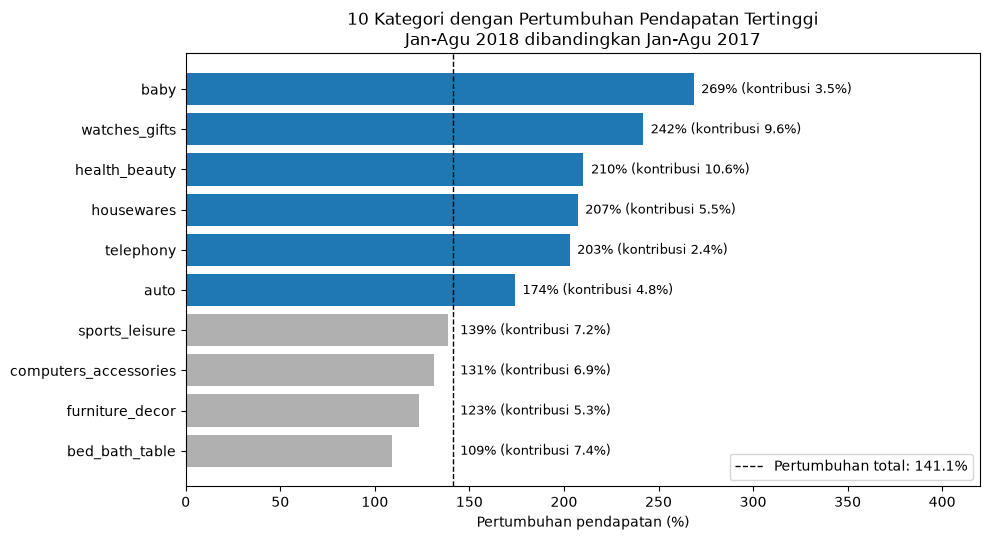

In [27]:
# pertumbuhan total dipakai sebagai garis pembanding
pertumbuhan_total = (total_2018_semua / total_2017 - 1) * 100

top_df = (pendapatan_df.sort_values("pertumbuhan_%", ascending=False)
          .head(10).sort_values("pertumbuhan_%"))

# biru untuk kategori di atas pertumbuhan total, abu-abu untuk yang di bawahnya
warna = ["#1f77b4" if x > pertumbuhan_total else "#b0b0b0" for x in top_df["pertumbuhan_%"]]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top_df.index, top_df["pertumbuhan_%"], color=warna)
ax.axvline(pertumbuhan_total, color="black", linestyle="--", linewidth=1,
           label=f"Pertumbuhan total: {pertumbuhan_total:.1f}%")

for i, (nilai, kontribusi) in enumerate(zip(top_df["pertumbuhan_%"], top_df["kontribusi_2018_%"])):
    ax.text(max(nilai, pertumbuhan_total) + 4, i, f"{nilai:.0f}% (kontribusi {kontribusi:.1f}%)", va="center", fontsize=9)

ax.set_title("10 Kategori dengan Pertumbuhan Pendapatan Tertinggi\nJan-Agu 2018 dibandingkan Jan-Agu 2017", fontsize=12)
ax.set_xlabel("Pertumbuhan pendapatan (%)")
ax.set_ylabel("")
ax.set_xlim(0, 420)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Pertanyaan 2:
##### Review score berdasarkan ketepatan pengiriman

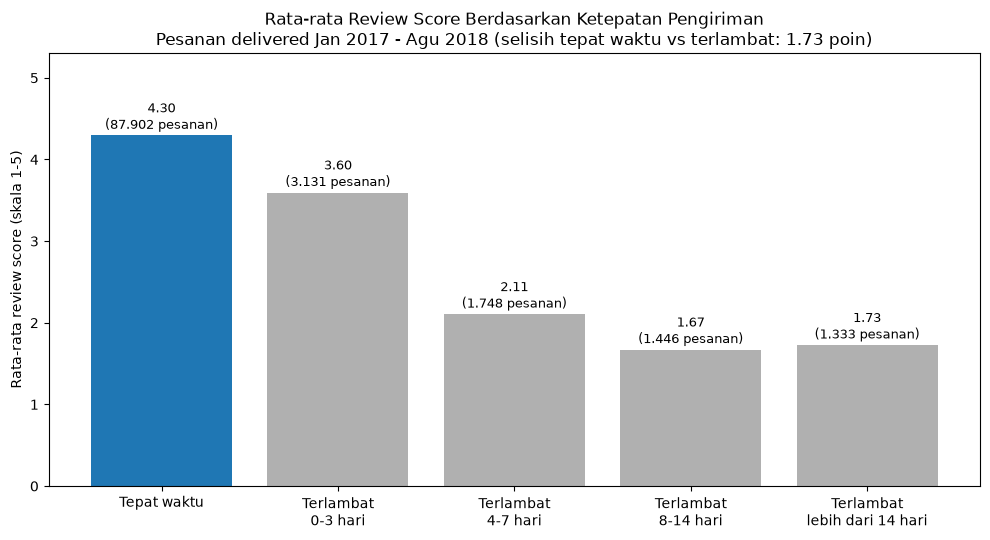

In [28]:
# menghitung skor rata-rata dan jumlah pesanan untuk tiap kelompok
skor_tepat = pengiriman_df[~pengiriman_df["terlambat"]]["review_score"]
skor_telat = terlambat_df.groupby("kelompok", observed=True)["review_score"].agg(["mean", "count"])

labels = ["Tepat waktu"] + [f"Terlambat\n{k}" for k in skor_telat.index]
nilai = [skor_tepat.mean()] + list(skor_telat["mean"])
jumlah = [skor_tepat.count()] + list(skor_telat["count"])

# biru untuk pesanan tepat waktu, abu-abu untuk yang terlambat
warna = ["#1f77b4"] + ["#b0b0b0"] * len(skor_telat)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(labels, nilai, color=warna)

for i, (n, j) in enumerate(zip(nilai, jumlah)):
    ax.text(i, n + 0.08, f"{n:.2f}\n({j:,} pesanan)".replace(",", "."), ha="center", fontsize=9)

selisih = nilai[0] - skor_telat["mean"].mul(skor_telat["count"]).sum() / skor_telat["count"].sum()

ax.set_title("Rata-rata Review Score Berdasarkan Ketepatan Pengiriman\n"
             f"Pesanan delivered Jan 2017 - Agu 2018 (selisih tepat waktu vs terlambat: {selisih:.2f} poin)",
             fontsize=12)
ax.set_ylabel("Rata-rata review score (skala 1-5)")
ax.set_ylim(0, 5.3)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Pertanyaan 1: Enam kategori tumbuh di atas pertumbuhan total pendapatan (141,1%), yaitu baby, watches_gifts, health_beauty, housewares, telephony, dan auto. Di antaranya, health_beauty (kontribusi 10,6%) dan watches_gifts (kontribusi 9,6%) paling berdampak karena tumbuh cepat sekaligus berkontribusi besar, sedangkan baby tumbuh paling tinggi (269%) tetapi kontribusinya hanya 3,5%.
- Pertanyaan 2: Pesanan tepat waktu mendapat rata-rata review score 4,30, sedangkan pesanan terlambat jauh lebih rendah. Selisih keseluruhannya 1,73 poin.
- Skor turun tajam setelah keterlambatan melewati 3 hari, dari 3,60 (0-3 hari) menjadi 2,11 (4-7 hari), lalu bertahan di kisaran 1,7 untuk keterlambatan yang lebih lama.

## Analisis Lanjutan (Opsional)

### RFM Analysis
RFM Analysis mengelompokkan pelanggan berdasarkan tiga ukuran perilaku pembelian:

- **Recency:** jumlah hari sejak pembelian terakhir.
- **Frequency:** jumlah pesanan yang dilakukan pelanggan.
- **Monetary:** total pengeluaran pelanggan (dalam Real Brasil, R$).

Tujuannya mengidentifikasi pelanggan bernilai tinggi dan pelanggan yang perlu diaktifkan kembali.

In [29]:
# customer_unique_id dipakai karena customer_id berubah di setiap pesanan
rfm_orders = pengiriman_df.merge(customers_df[["customer_id", "customer_unique_id"]], on="customer_id")

nilai_pesanan = order_items_df.groupby("order_id", as_index=False)["price"].sum()
rfm_orders = rfm_orders.merge(nilai_pesanan, on="order_id")

# tanggal acuan: sehari setelah pembelian terakhir di data
tanggal_acuan = rfm_orders["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm_df = rfm_orders.groupby("customer_unique_id").agg(
    recency=("order_purchase_timestamp", lambda x: (tanggal_acuan - x.max()).days),
    frequency=("order_id", "nunique"),
    monetary=("price", "sum")
).reset_index()

print("Jumlah pelanggan:", rfm_df.shape[0])
print(rfm_df["frequency"].value_counts().sort_index().head())
rfm_df.describe().round(1)

Jumlah pelanggan: 93096
frequency
1    90307
2     2562
3      180
4       28
5        9
Name: count, dtype: int64


,recency,frequency,monetary
count,93096.0,93096.0,93096.0
mean,236.7,1.0,141.6
std,150.9,0.2,215.8
min,1.0,1.0,0.8
25%,114.0,1.0,47.6
50%,218.0,1.0,89.7
75%,345.0,1.0,154.2
max,602.0,15.0,13440.0


##### Segmentasi Pelanggan
Pelanggan dikelompokkan secara manual karena 97% pelanggan hanya membeli satu kali, sehingga skor Frequency berbasis kuantil tidak dapat dipakai. Pelanggan dengan dua pesanan atau lebih menjadi segmen tersendiri. Pelanggan yang membeli sekali dibagi berdasarkan Recency (median) dan Monetary (kuartil teratas).

In [30]:
batas_recency = rfm_df["recency"].median()
batas_monetary = rfm_df["monetary"].quantile(0.75)

kondisi = [
    rfm_df["frequency"] >= 2,
    (rfm_df["recency"] <= batas_recency) & (rfm_df["monetary"] >= batas_monetary),
    (rfm_df["recency"] > batas_recency) & (rfm_df["monetary"] >= batas_monetary),
    rfm_df["recency"] <= batas_recency,
]
nama_segmen = ["Pelanggan Berulang", "Baru - Bernilai Tinggi", "Lama - Bernilai Tinggi", "Baru - Nilai Biasa"]

# pelanggan yang tidak masuk kondisi mana pun menjadi "Lama - Nilai Biasa"
rfm_df["segmen"] = np.select(kondisi, nama_segmen, default="Lama - Nilai Biasa")

ringkasan_rfm = rfm_df.groupby("segmen").agg(
    jumlah=("customer_unique_id", "count"),
    rata_monetary=("monetary", "mean"),
    total_monetary=("monetary", "sum")
).round(1)
ringkasan_rfm["persen_pelanggan"] = (ringkasan_rfm["jumlah"] / ringkasan_rfm["jumlah"].sum() * 100).round(1)
ringkasan_rfm["persen_pendapatan"] = (ringkasan_rfm["total_monetary"] / ringkasan_rfm["total_monetary"].sum() * 100).round(1)

ringkasan_rfm.sort_values("jumlah", ascending=False)

,jumlah,rata_monetary,total_monetary,persen_pelanggan,persen_pendapatan
segmen,,,,,
Lama - Nilai Biasa,34381,69.5,2389315.8,36.9,18.1
Baru - Nilai Biasa,34327,71.1,2442103.1,36.9,18.5
Lama - Bernilai Tinggi,10902,352.5,3843194.8,11.7,29.2
Baru - Bernilai Tinggi,10697,353.4,3779809.2,11.5,28.7
Pelanggan Berulang,2789,260.1,725355.0,3.0,5.5


##### Perbandingan Segmen Pelanggan

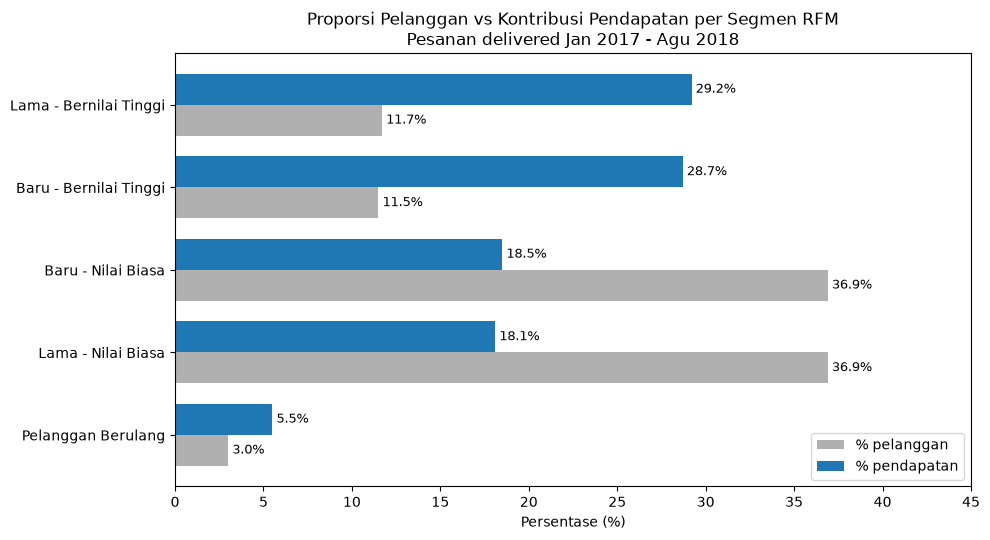

In [31]:
plot_df = ringkasan_rfm.sort_values("persen_pendapatan")[["persen_pelanggan", "persen_pendapatan"]]

ax = plot_df.plot(kind="barh", figsize=(10, 5.5), color=["#b0b0b0", "#1f77b4"], width=0.75)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)

ax.set_title("Proporsi Pelanggan vs Kontribusi Pendapatan per Segmen RFM\nPesanan delivered Jan 2017 - Agu 2018", fontsize=12)
ax.set_xlabel("Persentase (%)")
ax.set_ylabel("")
ax.set_xlim(0, 45)
ax.legend(["% pelanggan", "% pendapatan"], loc="lower right")
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Sebanyak 97% pelanggan hanya membeli satu kali, sehingga segmentasi RFM dibuat manual dan Frequency hanya membedakan pelanggan berulang (2 pesanan atau lebih) dari pelanggan sekali beli. Pelanggan "Baru" adalah yang terakhir membeli dalam 218 hari terakhir (median recency), sedangkan "Lama" lebih dari itu.
- Pada grafik, segmen Bernilai Tinggi (Baru dan Lama) hanya 23,2% dari pelanggan, tetapi menyumbang 57,9% pendapatan, dengan rata-rata pengeluaran sekitar R$ 353 per pelanggan.
- Segmen Lama - Bernilai Tinggi (10.902 pelanggan, 29,2% pendapatan) adalah pelanggan bernilai besar yang sudah lama tidak membeli, sehingga menjadi sasaran utama kampanye pengaktifan kembali.
- Pelanggan Berulang hanya 3,0% dari pelanggan dan 5,5% dari pendapatan, yang menunjukkan retensi pelanggan masih lemah.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pendapatan pesanan delivered pada Januari-Agustus 2018 tumbuh 141,1% dibandingkan periode yang sama di 2017 (dari sekitar R$ 2,99 juta menjadi R$ 7,22 juta). Enam kategori tumbuh di atas angka tersebut, yaitu baby (268,6%), watches_gifts (241,8%), health_beauty (210,3%), housewares (207,2%), telephony (203,0%), dan auto (174,1%). Kategori health_beauty (kontribusi 10,6%) dan watches_gifts (9,6%) paling berdampak karena tumbuh cepat sekaligus berkontribusi besar, sedangkan baby tumbuh paling tinggi tetapi baru berkontribusi 3,5%. Pertumbuhan paling lambat terjadi pada cool_stuff (10,4%) dan luggage_accessories (25,5%).
- **Conclusion pertanyaan 2:** Pesanan yang tiba tepat waktu memiliki rata-rata review score 4,30, sedangkan pesanan yang terlambat 2,57, selisih 1,73 poin. Sebanyak 8,1% pesanan terlambat. Skor turun tajam ketika keterlambatan melewati 3 hari (3,60 pada 0-3 hari menjadi 2,11 pada 4-7 hari), lalu bertahan di kisaran 1,7 untuk keterlambatan yang lebih lama. Hasil ini menunjukkan hubungan, bukan bukti bahwa keterlambatan satu-satunya penyebab skor rendah.
- **Conclusion analisis lanjutan (RFM):** Sebanyak 97% pelanggan hanya membeli sekali. Segmen Bernilai Tinggi hanya 23,2% dari pelanggan tetapi menyumbang 57,9% pendapatan, sedangkan Pelanggan Berulang hanya 3,0% dari pelanggan dan 5,5% dari pendapatan.

**Rekomendasi Action Item:**
- Prioritaskan stok, promosi, dan penambahan seller pada kategori health_beauty dan watches_gifts yang tumbuh cepat dan berkontribusi besar. Pantau juga baby, housewares, dan telephony sebagai kategori yang sedang berkembang, serta evaluasi strategi pada cool_stuff dan luggage_accessories yang pertumbuhannya jauh di bawah rata-rata.
- Tekan keterlambatan pengiriman, terutama agar tidak melewati 3 hari dari estimasi, karena skor review turun tajam setelah batas tersebut. Langkah yang bisa dilakukan: memperbaiki akurasi estimasi pengiriman, mengevaluasi mitra logistik dan seller yang sering terlambat, serta memberi notifikasi lebih awal kepada pelanggan yang pesanannya berisiko terlambat.
- Jalankan kampanye pengaktifan kembali untuk segmen Lama - Bernilai Tinggi (10.902 pelanggan, 29,2% pendapatan), misalnya voucher atau penawaran personal, dan bangun program loyalitas untuk mendorong pembelian ulang karena retensi masih lemah.

## Menyimpan Data untuk Dashboard
Data hasil analisis digabung pada tingkat item pesanan dan disimpan sebagai `main_data.csv` agar dapat dipakai oleh dashboard Streamlit.

In [32]:
pengiriman_df["hari_telat"] = (
    pengiriman_df["order_delivered_customer_date"] - pengiriman_df["order_estimated_delivery_date"]
).dt.days

dashboard_df = (
    items_df[["order_id", "order_purchase_timestamp", "kategori", "price"]]
    .merge(pengiriman_df[["order_id", "terlambat", "hari_telat", "review_score"]], on="order_id")
    .merge(rfm_orders[["order_id", "customer_unique_id"]], on="order_id")
)

dashboard_df.to_csv("dashboard/main_data.csv", index=False)

print("Jumlah baris:", dashboard_df.shape[0])
print("Jumlah pesanan unik:", dashboard_df["order_id"].nunique())
dashboard_df.head()

Jumlah baris: 109872
Jumlah pesanan unik: 96203


,order_id,order_purchase_timestamp,kategori,price,terlambat,hari_telat,review_score,customer_unique_id
0,00010242fe8c5a6d1ba2dd792cb16214,2017-09-13 08:59:02,cool_stuff,58.90,False,-9,5.0,871766c5855e863f6eccc05f988b23cb
1,00018f77f2f0320c557190d7a144bdd3,2017-04-26 10:53:06,pet_shop,239.90,False,-3,4.0,eb28e67c4c0b83846050ddfb8a35d051
2,000229ec398224ef6ca0657da4fc703e,2018-01-14 14:33:31,furniture_decor,199.00,False,-14,5.0,3818d81c6709e39d06b2738a8d3a2474
3,00024acbcdf0a6daa1e931b038114c75,2018-08-08 10:00:35,perfumery,12.99,False,-6,4.0,af861d436cfc08b2c2ddefd0ba074622
4,00042b26cf59d7ce69dfabb4e55b4fd9,2017-02-04 13:57:51,garden_tools,199.90,False,-16,5.0,64b576fb70d441e8f1b2d7d446e483c5
